In [90]:
#Libraries
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.animation import FuncAnimation, PillowWriter
from astropy.time import Time
from pathlib import Path
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

<h3 style="color: #e19edc;"> Parámetros de las tres componentes de todos los espectros </h3>

In [3]:
datos_2018_2019 = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\Resultados perfiles halpha 2018 y 2019 priorizando el sector naranja.xlsx"
datos_2023 = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\resultados perfiles halpha 2023.xlsx"
datos_2024_2025_2026 = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\resultados perfiles halpha 2024, 2025 y 2026.xlsx"

In [11]:
ver_2018_2019 = pd.read_excel(datos_2018_2019, sheet_name="Sheet1")
ver_2023 = pd.read_excel(datos_2023, sheet_name="Sheet1")
ver_2024_2025_2026 = pd.read_excel(datos_2024_2025_2026, sheet_name="Sheet1")

<h4 style="color: #e19edc;"> Organización de los parámetros en común</h4>

In [ ]:
#En el 2023 quedarse solo con los datos con los que se logró calcular la velocidad heliocéntrica 

marco_tierra = "Tierra"
v23 = ver_2023[ver_2023["Marco"].str.strip() == marco_tierra].copy()

# En 2023 la velocidad observada se llama distinto (por el ajuste de la semilla)

v23 = v23.rename(columns={"Velocidad en espectro [km/s]": "Velocidad obs. [km/s]"})

cols = ["Época", "Componente", "Centro [Å]", "z", "Velocidad obs. [km/s]", "Velocidad heliocéntrica [km/s]",
       "Profundidad / Altura", "FWHM [Å]", "EW [Å]"]

a = ver_2018_2019.reindex(columns=cols).assign(Archivo="2018-2019")
b = v23.reindex(columns=cols).assign(Archivo="2023")
c = ver_2024_2025_2026.reindex(columns=cols).assign(Archivo="2024-2026")

df = pd.concat([a, b, c], ignore_index=True)
df["Componente"] = df["Componente"].str.strip()

print(df.groupby("Archivo")["Componente"].value_counts())

Archivo    Componente       
2018-2019  Absorción Cobalto    12
           Absorción Hα         12
           Emisión Azul Hα      12
2023       Absorción Cobalto     6
           Absorción Hα          6
           Emisión Azul Hα       6
2024-2026  Absorción Cobalto    24
           Absorción Hα         24
           Emisión Azul Hα      24
Name: count, dtype: int64


<h4 style="color: #e19edc;"> Transformación de la época en formato fecha</h4>

In [17]:
meses = {"Julio":7,"Agosto":8,"Septiembre":9,"Octubre":10,"Noviembre":11,"Diciembre":12}

def epoca_a_iso(texto):

    m = re.match(r"\s*([A-Za-záéíóú]+)\s+(\d{1,2})\s*-\s*(\d{4})", str(texto))

    if m is None:
        raise ValueError(f"No pude interpretar la época: {texto!r}")
    
    mes, dia, anio = m.groups()
    return f"{int(anio):04d}-{meses[mes]:02d}-{int(dia):02d}"

df["Época ISO"] = df["Época"].apply(epoca_a_iso)
tiempo = Time(df["Época ISO"].tolist(), format="iso", scale="utc")
df["MJD"] = tiempo.mjd
df["Fecha"] = pd.to_datetime(tiempo.datetime)

<h3 style="color: #e19edc;"> Gráficas</h3>

In [77]:
colores = {"Emisión Azul Hα": "turquoise", "Absorción Hα": "deepskyblue", "Absorción Cobalto": "purple"}
marcadores = {"Emisión Azul Hα": "o", "Absorción Hα": "s", "Absorción Cobalto": "^"}

parametros = {
    "Centro [Å]":                     "Centro observado [Å]",
    "z":                              "Corrimiento z",
    "Velocidad heliocéntrica [km/s]": "Velocidad heliocéntrica [km/s]",
    "Profundidad / Altura":           "Amplitud",
    "FWHM [Å]":                       "FWHM [Å]",
    "EW [Å]":                         "Ancho equivalente [Å]",
}


In [96]:
meses_español = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

def formato_mes_es(x, pos=None):
    
    fecha = mdates.num2date(x)
    return meses_español[fecha.month - 1]

<h5 style="color: #e19edc;"> Gráficas conjuntas de cada parámetro</h5>

In [97]:
def graficar_parametro(df, columna, etiqueta_y, carpeta="./Graficas parametros evolucion temporal/Graficas conjuntas",
                       ancho_minimo_meses=2):
    Path(carpeta).mkdir(parents=True, exist_ok=True)

    d = df.dropna(subset=[columna]).copy()
    d["Año"] = d["Fecha"].dt.year
    años = sorted(d["Año"].unique())

    rangos = {}
    for a in años:
        f = d.loc[d["Año"] == a, "Fecha"]
        inicio_año = pd.Timestamp(year=a, month=7, day=1)
        fin_año = pd.Timestamp(year=a + 1, month=7, day=1)

        ini = f.min().replace(day=1).normalize()                         
        fin = f.max().replace(day=1).normalize() + pd.offsets.MonthBegin(1)  
        fin = min(fin, fin_año)

        # Ancho mínimo
        while (fin.year - ini.year) * 12 + (fin.month - ini.month) < ancho_minimo_meses:

            if fin < fin_año:
                fin = fin + pd.offsets.MonthBegin(1)

            elif ini > inicio_año:
                ini = ini - pd.offsets.MonthBegin(1)

            else:
                break
        rangos[a] = (ini, fin)

    anchos = [(rangos[a][1] - rangos[a][0]).days for a in años]
    fig, axs = plt.subplots(1, len(años), figsize=(13, 4.5), sharey=True, gridspec_kw={"width_ratios": anchos, "wspace": 0.2},)
    axs = np.atleast_1d(axs)

    for i, (ax, a) in enumerate(zip(axs, años)):
        sub_año = d[d["Año"] == a]
        for comp, sub in sub_año.groupby("Componente"):
            ax.scatter(sub["Fecha"], sub[columna], color=colores.get(comp, "gray"), marker=marcadores.get(comp, "o"),
                       s=40, edgecolor="k", linewidth=0.3, label=comp)

        ax.set_xlim(*rangos[a])
        ax.set_title(str(a), fontweight="bold")
        ax.grid(alpha=0.3)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(formato_mes_es))

        if i > 0:
            ax.tick_params(left=False)

    axs[0].set_ylabel(etiqueta_y)

    por_etiqueta = {}
    for ax in axs:
        h, l = ax.get_legend_handles_labels()
        por_etiqueta.update(dict(zip(l, h)))

    fig.legend(por_etiqueta.values(), por_etiqueta.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.03),
               ncol=len(por_etiqueta), fontsize=9, frameon=False)

    fig.supxlabel("Fechas de observación", y=-0.02, fontsize=11)

    #fig.suptitle(f"Evolución temporal de {etiqueta_y}", fontsize=12, fontweight="bold", y=1.02)

    nombre = etiqueta_y.split("[")[0].strip().replace(" ", "_").replace("/", "_")
    plt.savefig(Path(carpeta) / f"{nombre}_vs_tiempo.png", dpi=150, bbox_inches="tight")
    plt.show()

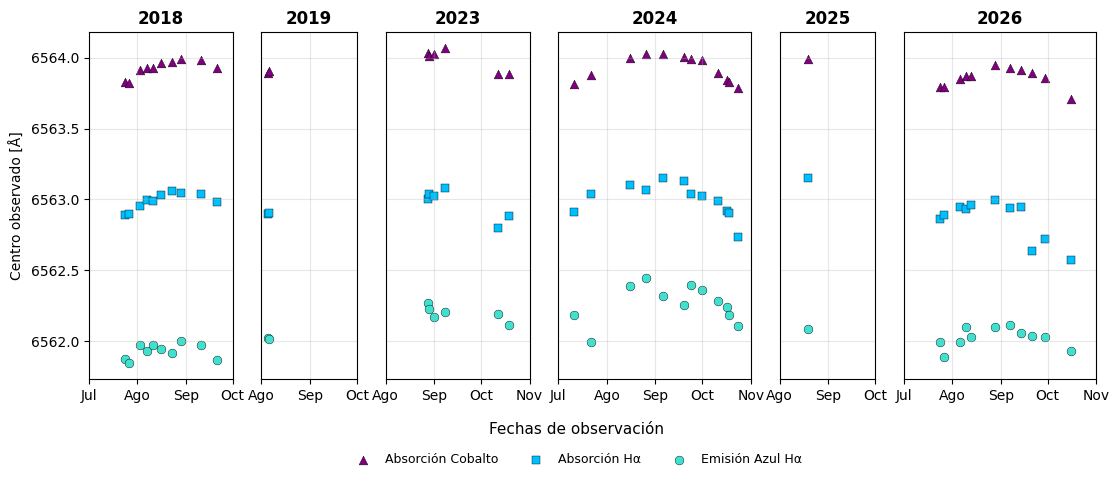

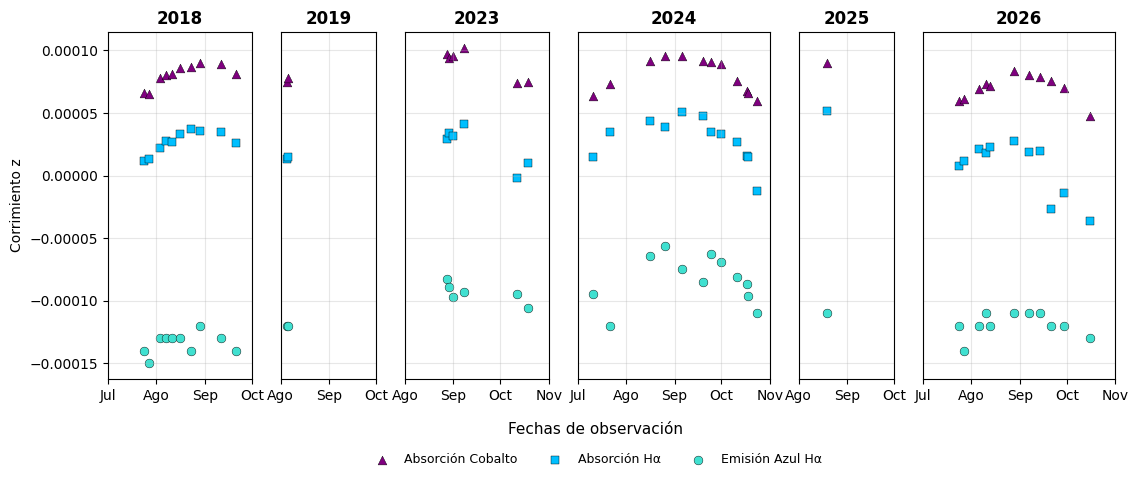

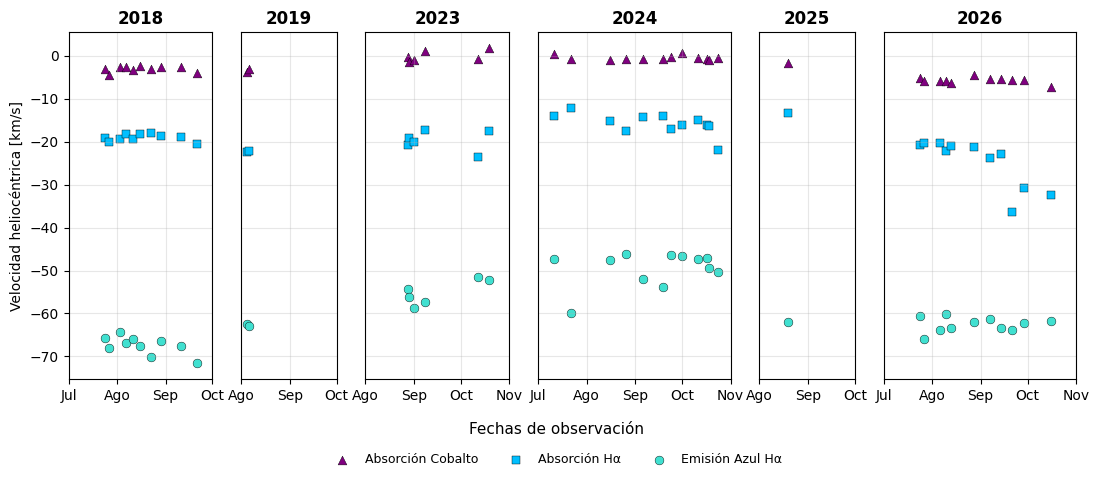

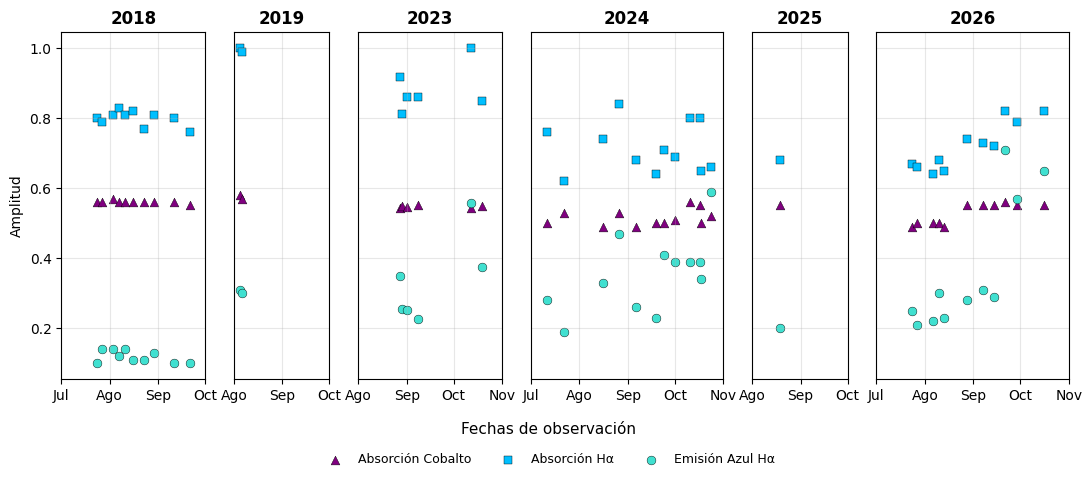

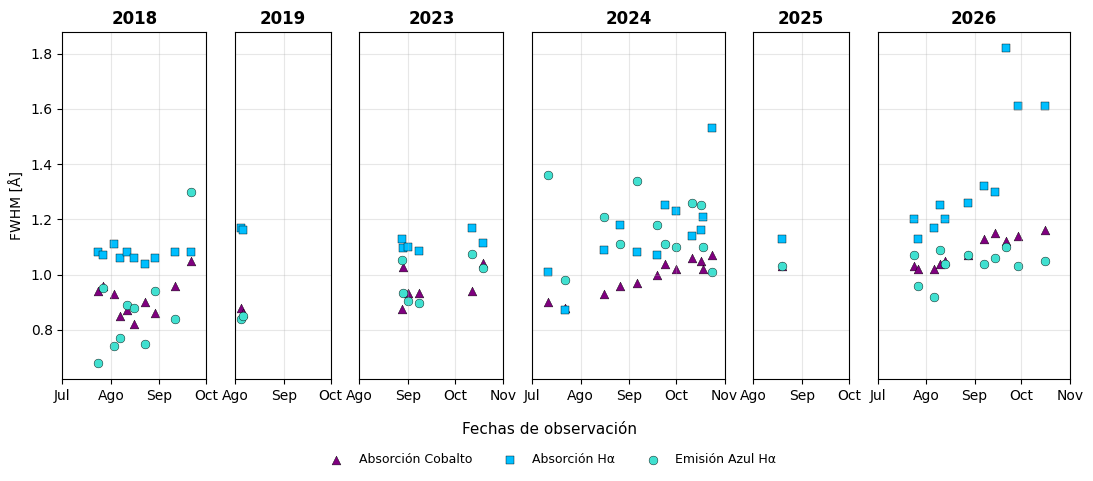

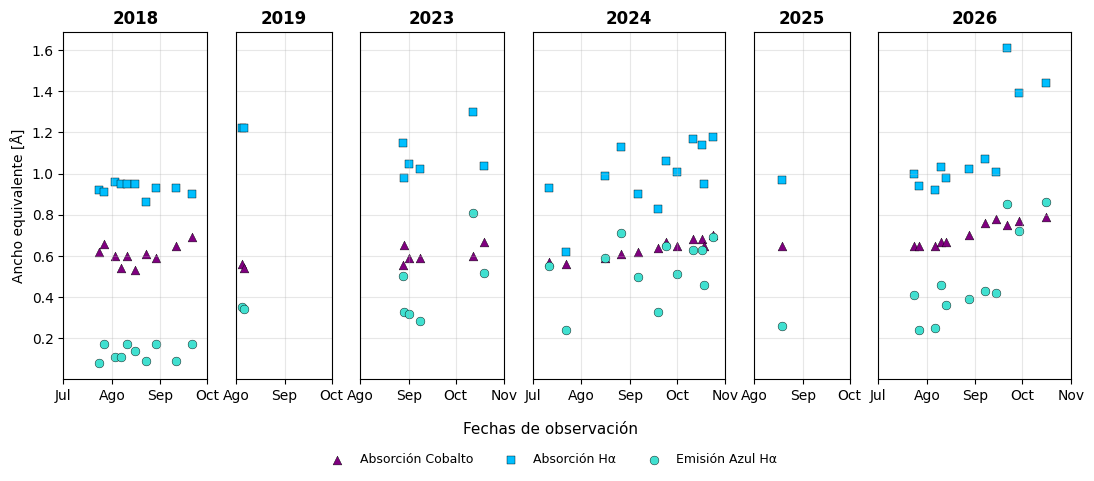

In [98]:
for col, etiqueta in parametros.items():
    graficar_parametro(df, col, etiqueta)

<h5 style="color: #e19edc;"> Gráficas indiviuales de cada parámetro</h5>

In [87]:
def graficar_parametro_individual(df, columna, etiqueta_y, componente=None, carpeta="./Graficas parametros evolucion temporal/Graficas individuales",
                                  ancho_minimo_meses=2):
    
    Path(carpeta).mkdir(parents=True, exist_ok=True)

    d = df.dropna(subset=[columna]).copy()

    if componente is not None:
        d = d[d["Componente"] == componente]

    if d.empty:
        print(f"Sin datos para {componente} en {columna}")

        return

    d["Año"] = d["Fecha"].dt.year
    años = sorted(d["Año"].unique())

    rangos = {}

    for a in años:
        f = d.loc[d["Año"] == a, "Fecha"]
        inicio_año = pd.Timestamp(year=a, month=7, day=1)
        fin_año = pd.Timestamp(year=a + 1, month=7, day=1)

        ini = f.min().replace(day=1).normalize()                         
        fin = f.max().replace(day=1).normalize() + pd.offsets.MonthBegin(1)  
        fin = min(fin, fin_año)

        # Ancho mínimo
        while (fin.year - ini.year) * 12 + (fin.month - ini.month) < ancho_minimo_meses:

            if fin < fin_año:
                fin = fin + pd.offsets.MonthBegin(1)

            elif ini > inicio_año:
                ini = ini - pd.offsets.MonthBegin(1)

            else:
                break
        rangos[a] = (ini, fin)

    anchos = [(rangos[a][1] - rangos[a][0]).days for a in años]
    fig, axs = plt.subplots(1, len(años), figsize=(13, 4.5), sharey=True, gridspec_kw={"width_ratios": anchos, "wspace": 0.2},)
    axs = np.atleast_1d(axs)

    for i, (ax, a) in enumerate(zip(axs, años)):
        sub_año = d[d["Año"] == a]
        for comp, sub in sub_año.groupby("Componente"):
            ax.scatter(sub["Fecha"], sub[columna], color=colores.get(comp, "gray"), marker=marcadores.get(comp, "o"),
                        s=40, edgecolor="k", linewidth=0.3, label=comp)

        ax.set_xlim(*rangos[a])
        ax.set_title(str(a), fontweight="bold")
        ax.grid(alpha=0.3)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

        if i > 0:
            ax.tick_params(left=False)

    axs[0].set_ylabel(etiqueta_y)

    etiqueta_titulo = etiqueta_y.split("[")[0].strip()
    titulo_comp = componente if componente else "todas las componentes"

    fig.suptitle(f"Evolución temporal de {etiqueta_titulo} en la componente de {titulo_comp}", fontsize=12, fontweight="bold", y=1.02)
    
    fig.supxlabel("Fechas de observación", y=-0.02, fontsize=10)

    if componente is None:

        por_etiqueta = {}

        for ax in axs:
            h, l = ax.get_legend_handles_labels()
            por_etiqueta.update(dict(zip(l, h)))

        fig.legend(por_etiqueta.values(), por_etiqueta.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.06),
                   ncol=len(por_etiqueta), fontsize=9, frameon=False)

    nombre = etiqueta_y.split("[")[0].strip().replace(" ", "_").replace("/", "_")

    sufijo = "" if componente is None else "_" + componente.replace(" ", "_")

    plt.savefig(Path(carpeta) / f"{nombre}{sufijo}_vs_tiempo.png", dpi=150, bbox_inches="tight")
    plt.show()
    

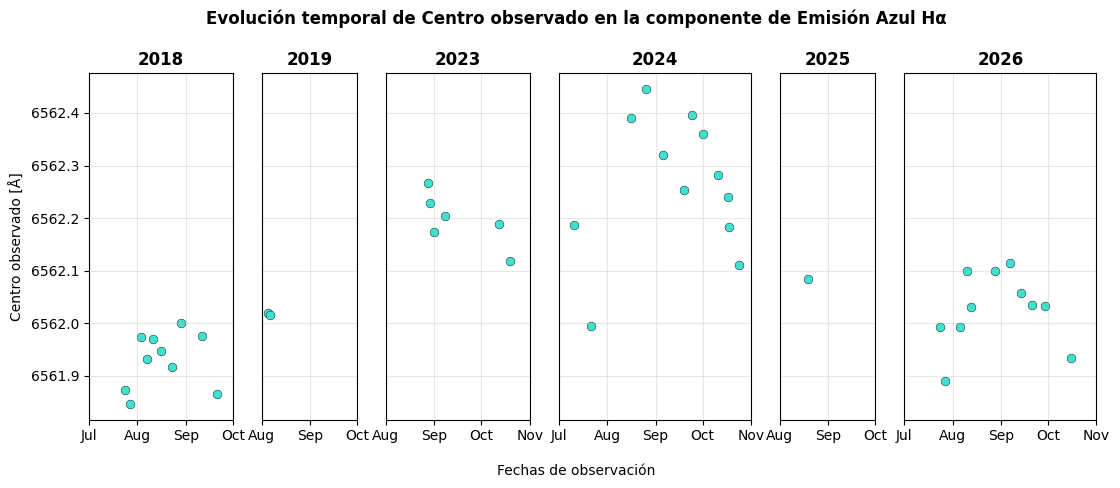

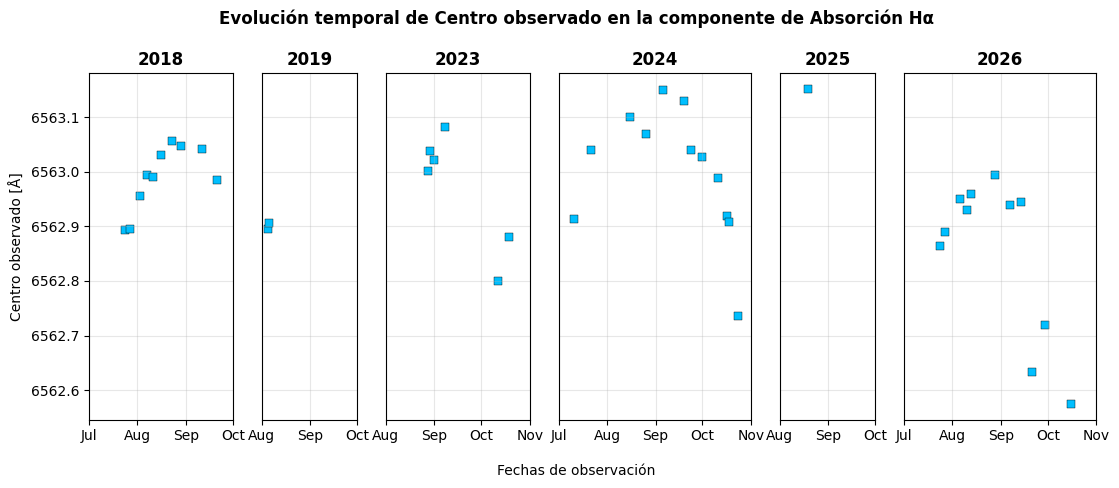

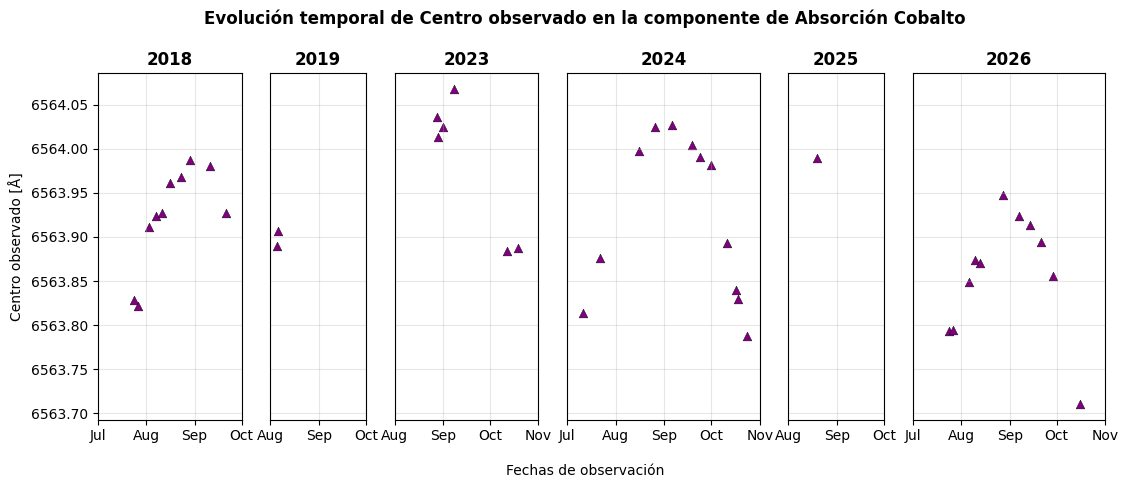

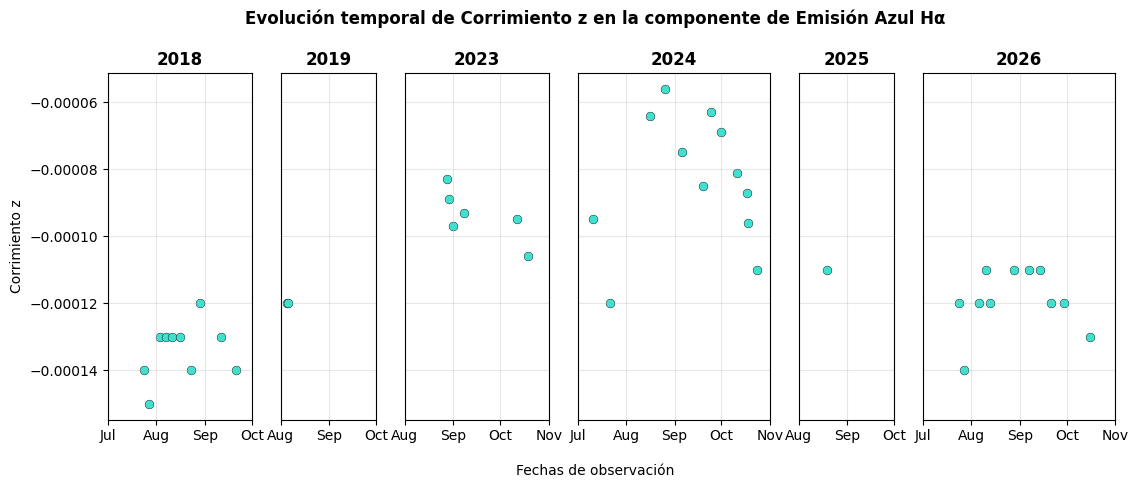

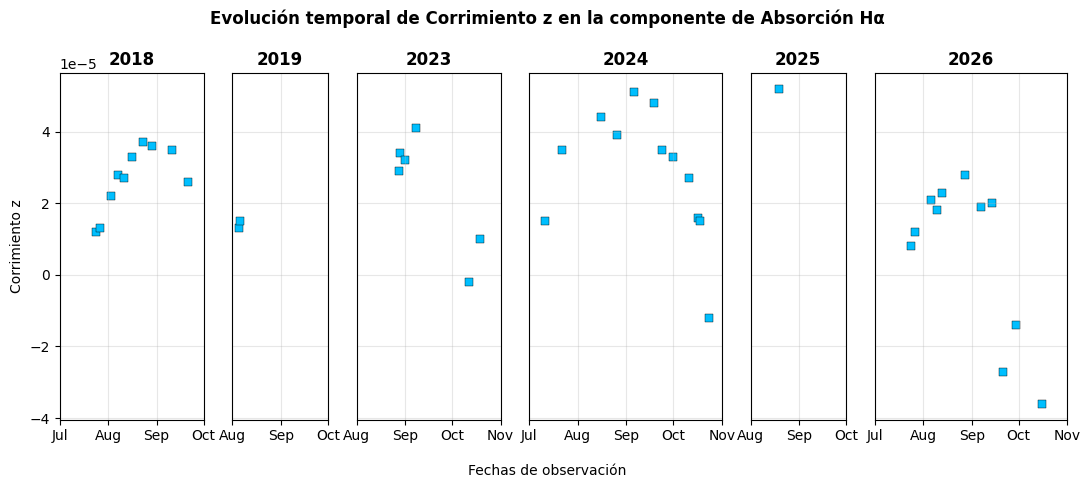

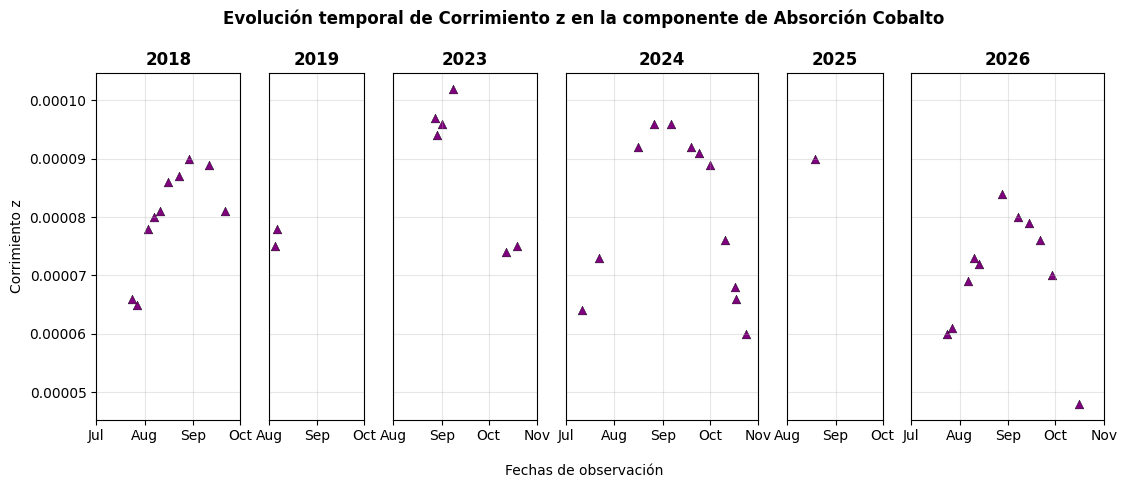

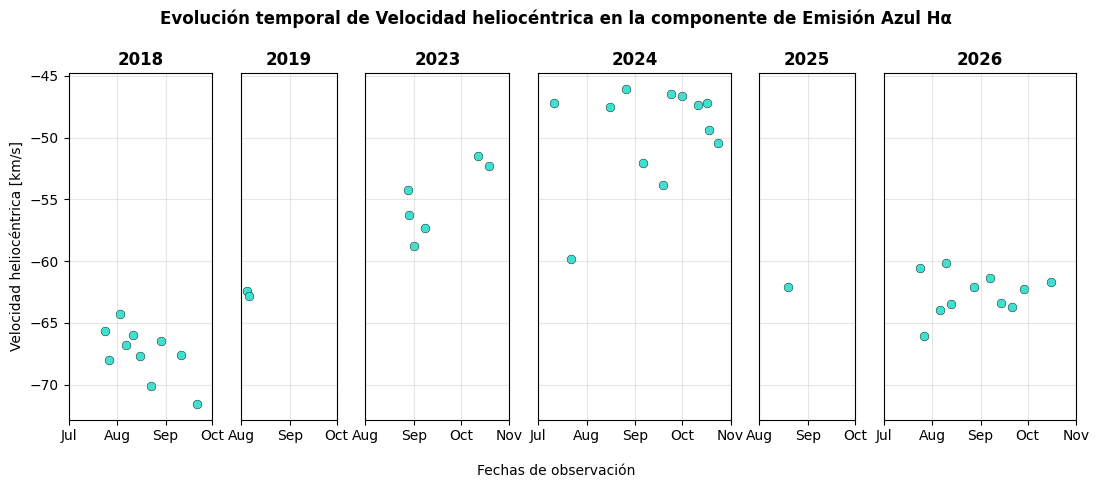

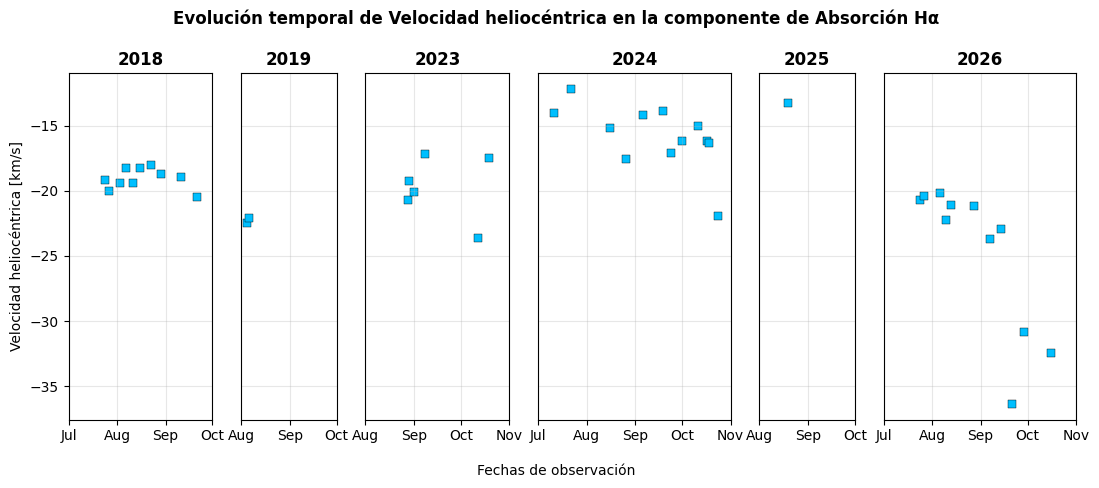

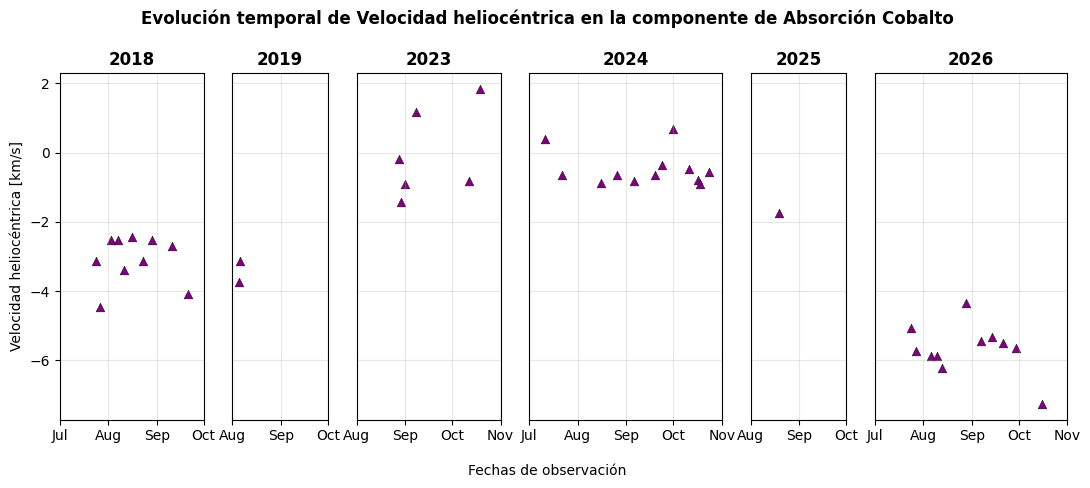

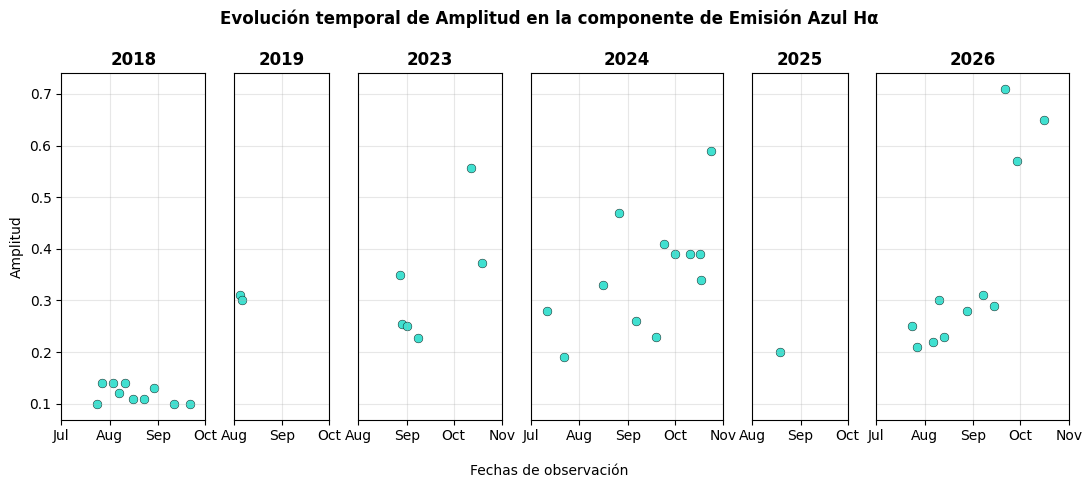

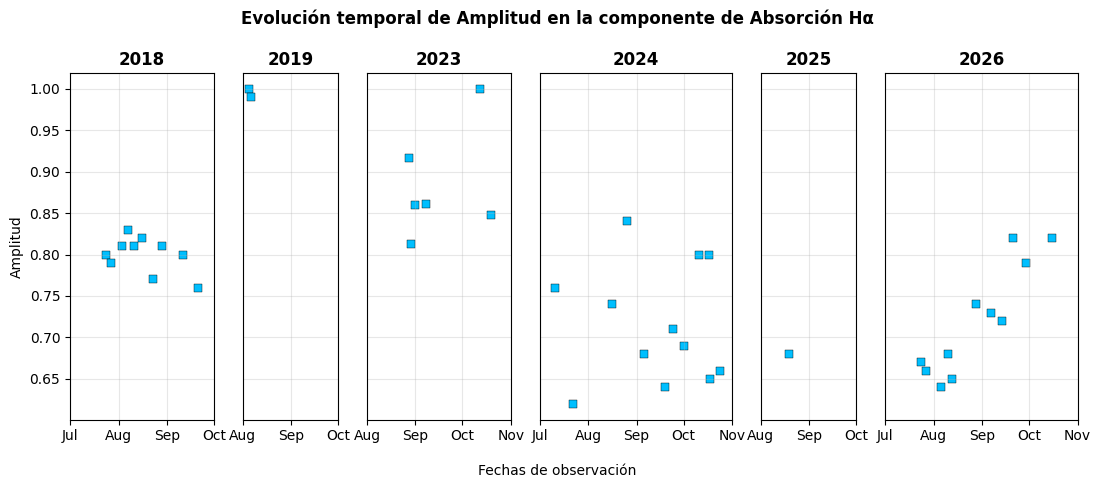

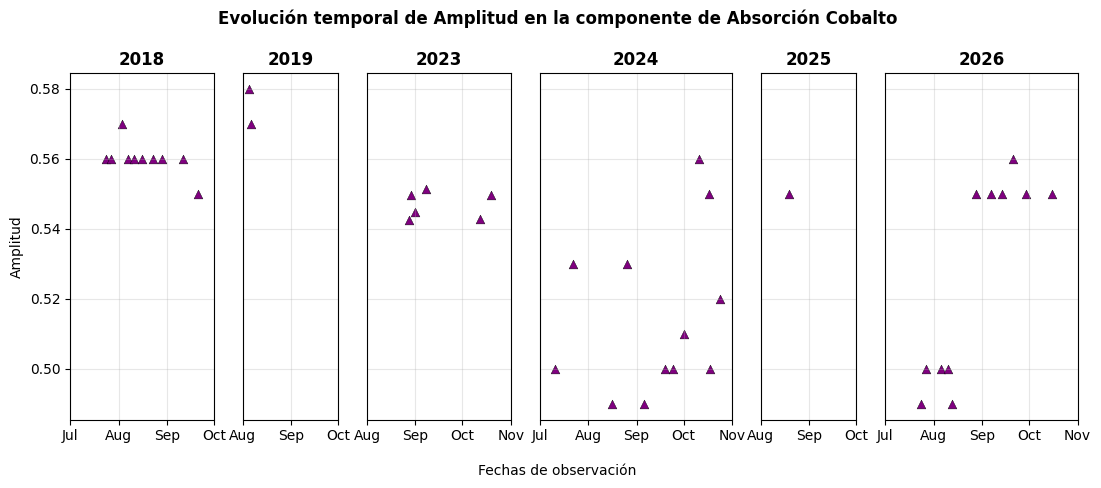

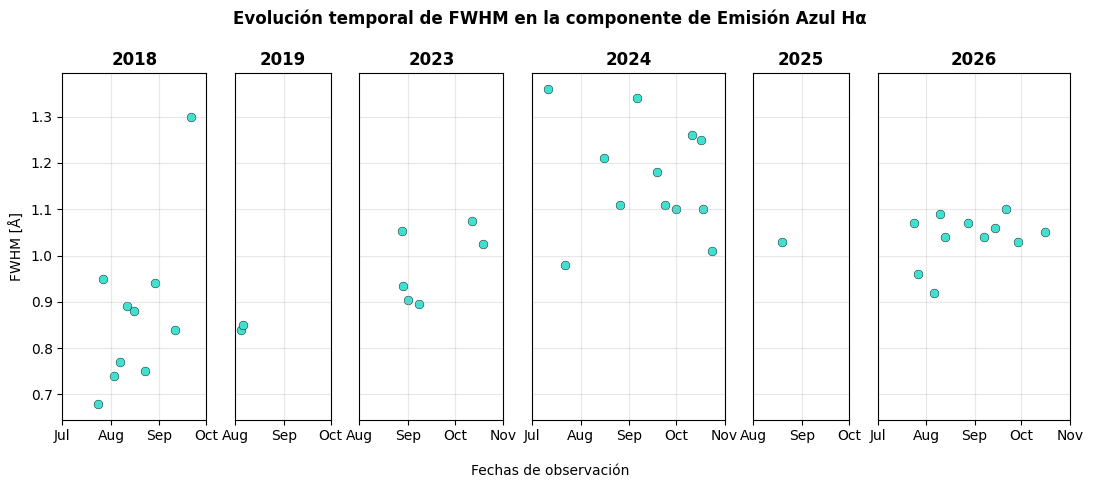

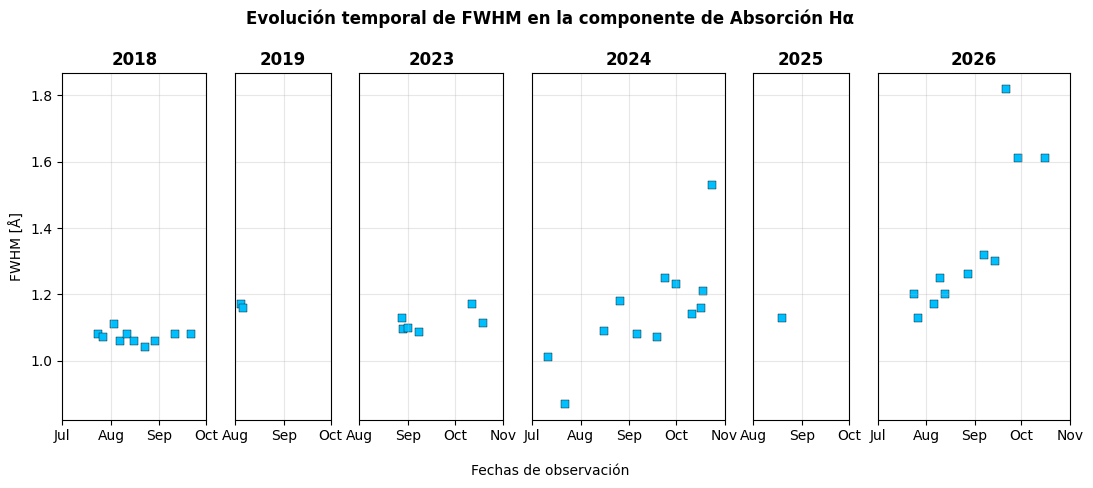

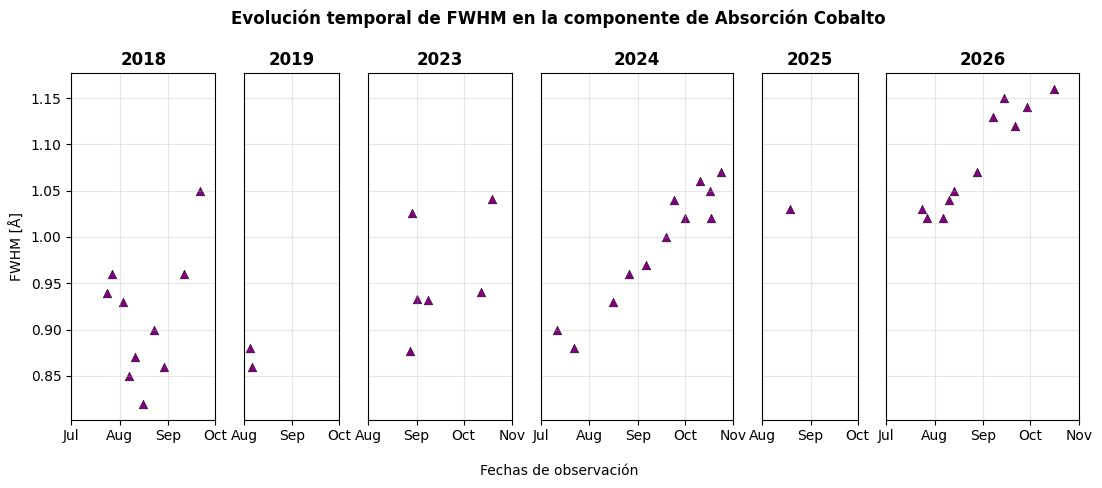

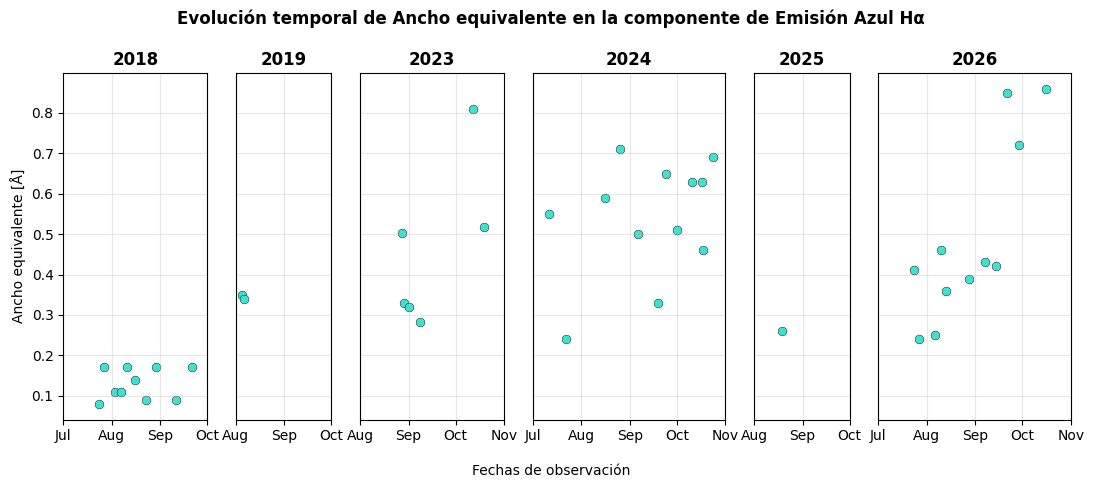

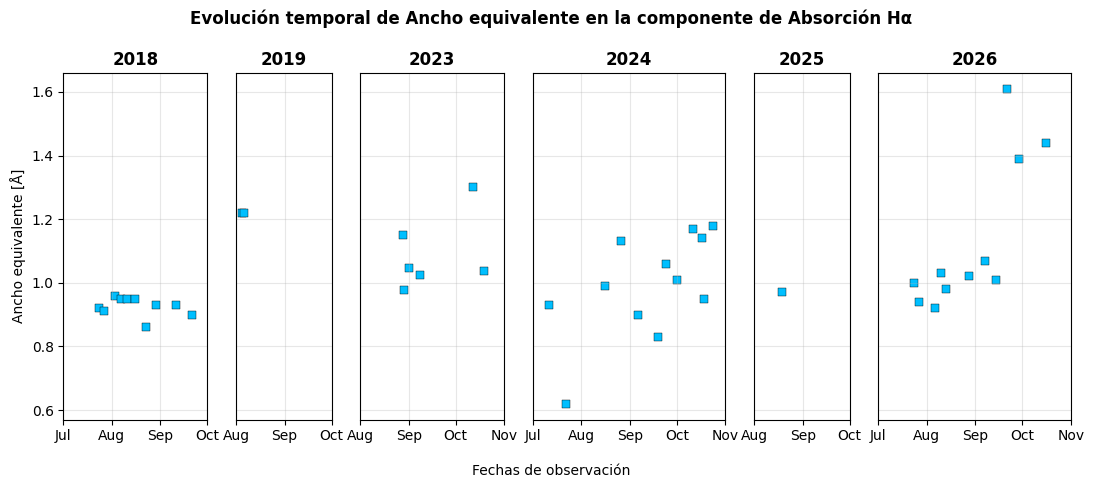

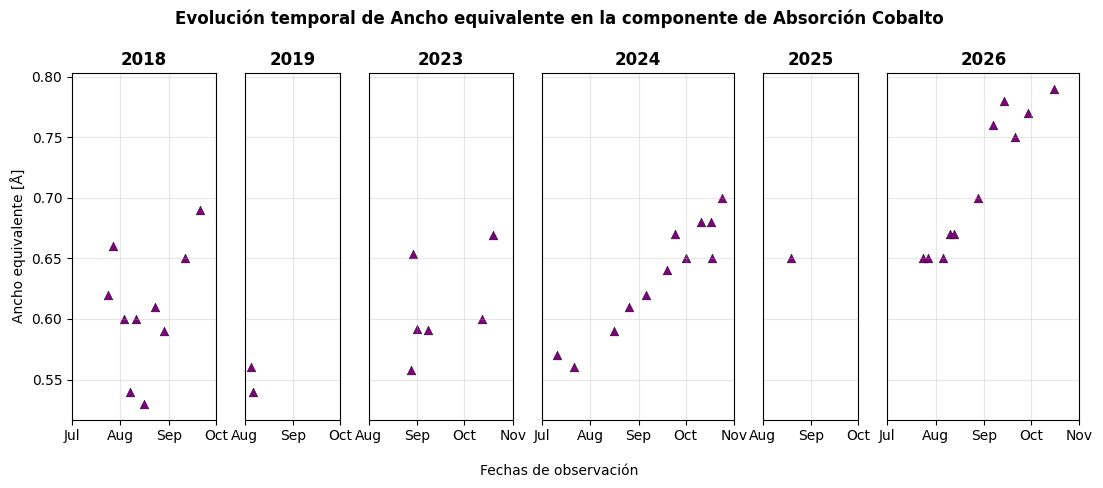

In [ ]:
for col, etiqueta in parametros.items():
    for comp in colores.keys():
        graficar_parametro_individual(df, col, etiqueta, componente=comp)